# Compare AM trip matrices

Compares three OMX trip matrices named in `settings.yaml` (`paths.`):

| Label | Key | Contents |
|---|---|---|
| **A** | `abm_omx_from_abm_trips_csv` | ABM `tripData.csv` → AM peak (periods 9–14) car trips, built by `trips_to_trip_matrix.py`; one matrix `trips`, **divided by `volume_time_scale`** (per hour) |
| **B** | `abm_trips_omx` | ABM native `tripsAM.OMX`; one matrix per mode (auto = DA/SR2/SR3 ± toll) |
| **C** | `t171_2020_taz_trips_omx` | PECAS T171 2020 TAZ trips; `work` + `non-work` |

Caveats: units (person vs vehicle trips), time period and zone systems differ between sources, so the
notebook reports both raw totals and share-normalised comparisons. Run cell by cell; each cell prints a sanity check.

In [2]:
# 1. Imports and config

import os
import sys
from itertools import combinations
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import openmatrix as omx
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from config import load_settings

settings = load_settings()
PATHS = {
    'A': settings['paths']['abm_omx_from_abm_trips_csv'],
    'B': settings['paths']['abm_trips_omx'],
    'C': settings['paths']['t171_2020_taz_trips_omx'],
}
LABELS = {'A': 'ABM CSV→OMX', 'B': 'ABM tripsAM', 'C': 'T171 2020'}
# Fixed color per source so each looks the same in every plot
SOURCE_COLORS = {'A': '#2a78d6', 'B': '#eb6834', 'C': '#1baf7a'}
PAIRS = list(combinations(PATHS, 2))  # (A,B), (A,C), (B,C)

pd.options.display.float_format = '{:,.3f}'.format
for k, p in PATHS.items():
    print(f"{k} {LABELS[k]:<12} exists={os.path.exists(p)}  {p}")

A ABM CSV→OMX  exists=True  /nfs/samba/ProjectWork/Atlanta PECAS 107080x0/2026 Project/Assignment_Simplified/aequilibrae_am/matrices/tripData_am3_cars.omx
B ABM tripsAM  exists=True  /nfs/samba/ProjectWork/Atlanta PECAS 107080x0/2026 Project/Assignment_Simplified/tripsAM.OMX
C T171 2020    exists=True  /nfs/samba/ProjectWork/Atlanta PECAS 107080x0/2026 Project/Assignment_Simplified/T171/2020/taz_trips.omx


In [3]:
# 2. Inspect files (headers + per-matrix sums, nothing kept in memory)

def describe_omx(path):
    with omx.open_file(path, 'r') as f:
        mappings = {m: len(f.mapping(m)) for m in f.list_mappings()}
        rows = [{'matrix': n, 'sum': float(f[n][:].sum())} for n in f.list_matrices()]
        print(f"{path}\n  shape={tuple(int(s) for s in f.shape())}  mappings={mappings or 'none'}")
    return pd.DataFrame(rows)

file_info = pd.concat({k: describe_omx(p) for k, p in PATHS.items()}, names=['source']).droplevel(1)
file_info

/nfs/samba/ProjectWork/Atlanta PECAS 107080x0/2026 Project/Assignment_Simplified/aequilibrae_am/matrices/tripData_am3_cars.omx
  shape=(6032, 6032)  mappings={'main_index': 6032}
/nfs/samba/ProjectWork/Atlanta PECAS 107080x0/2026 Project/Assignment_Simplified/tripsAM.OMX
  shape=(5922, 5922)  mappings=none
/nfs/samba/ProjectWork/Atlanta PECAS 107080x0/2026 Project/Assignment_Simplified/T171/2020/taz_trips.omx
  shape=(5922, 5922)  mappings={'zone number': 5922}


,matrix,sum
source,,
A,trips,"1,202,037.667"
B,BIKE,"26,756.000"
B,DA,"2,378,518.000"
B,DATOLL,"43,071.000"
B,EMPTY,"43,609.760"
B,KNR_ALL_WLK,"4,117.000"
B,KNR_PRM_WLK,"5,101.000"
B,PNR_ALL_WLK,"2,096.000"
B,PNR_PRM_WLK,"15,568.000"


In [4]:
# 2c. Sum work and non-work trips in the T171 2020 trip CSV

t171_trips_csv = settings['paths']['t171_2020_taz_trips_csv']

t171_type_counts = pd.read_csv(t171_trips_csv, usecols=['type'])['type'].value_counts()

t171_work = t171_type_counts.get('work', 0)
t171_non_work = t171_type_counts.get('non-work', 0)
t171_total = t171_work + t171_non_work

t171_summary = pd.DataFrame({
    'trip type': ['work', 'non-work', 'total'],
    'trips': [t171_work, t171_non_work, t171_total],
})
t171_summary['share'] = t171_summary['trips'] / t171_total

display(t171_summary)

print(f"T171 CSV: {t171_trips_csv}")
print(f"Work trips:     {t171_work:>12,}")
print(f"Non-work trips: {t171_non_work:>12,}")
print(f"Total trips:    {t171_total:>12,}")

,trip type,trips,share
0,work,1064394,0.404
1,non-work,1568912,0.596
2,total,2633306,1.000


T171 CSV: /nfs/samba/ProjectWork/Atlanta PECAS 107080x0/2026 Project/Assignment_Simplified/T171/2020/tazTrips.csv
Work trips:        1,064,394
Non-work trips:    1,568,912
Total trips:       2,633,306


In [5]:
# 2d. Sum work and non-work trips in the T171 2020 LUZ trip CSV

t171_luz_trips_csv = settings['paths']['t171_2020_luz_trips_csv']

t171_luz_trips = pd.read_csv(
    t171_luz_trips_csv,
    usecols=['non-work', 'work'],
)

t171_luz_work = t171_luz_trips['work'].sum()
t171_luz_non_work = t171_luz_trips['non-work'].sum()
t171_luz_total = t171_luz_work + t171_luz_non_work

t171_luz_summary = pd.DataFrame({
    'trip type': ['work', 'non-work', 'total'],
    'trips': [t171_luz_work, t171_luz_non_work, t171_luz_total],
})
t171_luz_summary['share'] = t171_luz_summary['trips'] / t171_luz_total

display(t171_luz_summary)

print(f"T171 LUZ CSV: {t171_luz_trips_csv}")
print(f"Work trips:     {t171_luz_work:>12,.0f}")
print(f"Non-work trips: {t171_luz_non_work:>12,.0f}")
print(f"Total trips:    {t171_luz_total:>12,.0f}")

,trip type,trips,share
0,work,"1,064,553.000",0.295
1,non-work,"2,542,483.000",0.705
2,total,"3,607,036.000",1.000


T171 LUZ CSV: /nfs/samba/ProjectWork/Atlanta PECAS 107080x0/2026 Project/Assignment_Simplified/T171/2020/LUZTrips.csv
Work trips:        1,064,553
Non-work trips:    2,542,483
Total trips:       3,607,036


In [6]:
# 2e. Count trips in the T171 2020 LUZ OMX

settings = load_settings()

t171_luz_trips_omx = settings['paths'].get(
    't171_2020_luz_trips_omx',
    os.path.join(settings['paths']['folder'], 'T171', '2020', 'luz_trips.omx'),
)

with omx.open_file(t171_luz_trips_omx, 'r') as f:
    print(f"T171 LUZ OMX: {t171_luz_trips_omx}")
    print(f"Shape: {tuple(int(s) for s in f.shape())}")
    print(f"Matrices: {f.list_matrices()}")
    print(f"Mappings: {f.list_mappings() or 'none'}")

    t171_luz_omx_summary = pd.DataFrame([
        {
            'matrix': name,
            'trips': float(f[name][:].sum()),
            'nonzero cells': int(np.count_nonzero(f[name][:])),
        }
        for name in f.list_matrices()
    ])

t171_luz_omx_total = t171_luz_omx_summary['trips'].sum()

display(t171_luz_omx_summary)

print(f"Total trips in T171 LUZ OMX: {t171_luz_omx_total:,.0f}")

T171 LUZ OMX: /nfs/samba/ProjectWork/Atlanta PECAS 107080x0/2026 Project/Assignment_Simplified/T171/2020/luz_trips.omx
Shape: (1035, 1035)
Matrices: ['non-work', 'work']
Mappings: ['zone number']


,matrix,trips,nonzero cells
0,non-work,"2,542,483.000",325321
1,work,"1,064,553.000",272944


Total trips in T171 LUZ OMX: 3,607,036


In [7]:
# 2f. T171 LUZ OMX total excluding external trips (any trip to or from LUZ 2000)

EXTERNAL_LUZ = 2000

with omx.open_file(t171_luz_trips_omx, 'r') as f:
    luz_to_idx = f.mapping(f.list_mappings()[0])
    ext = luz_to_idx[EXTERNAL_LUZ]

    rows = []
    for name in f.list_matrices():
        m = np.asarray(f[name][:], dtype=np.float64)
        total = m.sum()
        # trips touching LUZ 2000: row + column, minus the 2000->2000 cell counted twice
        external = m[ext, :].sum() + m[:, ext].sum() - m[ext, ext]
        rows.append({
            'matrix': name,
            'total trips': total,
            f'trips to/from LUZ {EXTERNAL_LUZ}': external,
            'internal trips': total - external,
        })

t171_luz_internal_summary = pd.DataFrame(rows).set_index('matrix')
t171_luz_internal_summary.loc['total'] = t171_luz_internal_summary.sum()
t171_luz_internal_summary['external %'] = (
    100 * t171_luz_internal_summary[f'trips to/from LUZ {EXTERNAL_LUZ}']
    / t171_luz_internal_summary['total trips']
)

display(t171_luz_internal_summary)

t171_luz_internal_total = t171_luz_internal_summary.loc['total', 'internal trips']
print(f"Total trips in T171 LUZ OMX excluding LUZ {EXTERNAL_LUZ}: {t171_luz_internal_total:,.0f}")

,total trips,trips to/from LUZ 2000,internal trips,external %
matrix,,,,
non-work,"2,542,483.000","974,056.000","1,568,427.000",38.311
work,"1,064,553.000",0.000,"1,064,553.000",0.000
total,"3,607,036.000","974,056.000","2,632,980.000",27.004


Total trips in T171 LUZ OMX excluding LUZ 2000: 2,632,980


In [8]:
# 2b. B auto vehicle-equivalent total: DA + DATOLL + SR2/2 + SR2TOLL/2 + SR3/3 + SR3TOLL/3

B_VEHICLE_EQUIV_WEIGHTS = {
    'DA': 1,
    'DATOLL': 1,
    'SR2': 1 / 2,
    'SR2TOLL': 1 / 2,
    'SR3': 1 / 3,
    'SR3TOLL': 1 / 3,
}

with omx.open_file(PATHS['B'], 'r') as f:
    b_vehicle_equiv_parts = pd.DataFrame([
        {
            'matrix': name,
            'raw sum': float(f[name][:].sum()),
            'weight': weight,
            'weighted sum': float(f[name][:].sum()) * weight,
        }
        for name, weight in B_VEHICLE_EQUIV_WEIGHTS.items()
    ])

b_vehicle_equiv_total = b_vehicle_equiv_parts['weighted sum'].sum()

display(b_vehicle_equiv_parts)
print(f"B vehicle-equivalent total: {b_vehicle_equiv_total:,.3f}")

,matrix,raw sum,weight,weighted sum
0,DA,"2,378,518.000",1.000,"2,378,518.000"
1,DATOLL,"43,071.000",1.000,"43,071.000"
2,SR2,"568,788.500",0.500,"284,394.250"
3,SR2TOLL,"1,464.000",0.500,732.000
4,SR3,"224,916.300",0.333,"74,972.100"
5,SR3TOLL,441.400,0.333,147.133


B vehicle-equivalent total: 2,781,834.483


In [9]:
# 2b. B auto vehicle-equivalent total: DA + DATOLL + SR2 + SR2TOLL + SR3 + SR3TOLL

B_VEHICLE_EQUIV_WEIGHTS = {
    'DA': 1,
    'DATOLL': 1,
    'SR2': 1,
    'SR2TOLL': 1,
    'SR3': 1,
    'SR3TOLL': 1,
}

with omx.open_file(PATHS['B'], 'r') as f:
    b_vehicle_equiv_parts = pd.DataFrame([
        {
            'matrix': name,
            'raw sum': float(f[name][:].sum()),
            'weight': weight,
            'weighted sum': float(f[name][:].sum()) * weight,
        }
        for name, weight in B_VEHICLE_EQUIV_WEIGHTS.items()
    ])

b_vehicle_equiv_total = b_vehicle_equiv_parts['weighted sum'].sum()

display(b_vehicle_equiv_parts)
print(f"B vehicle-equivalent total: {b_vehicle_equiv_total:,.3f}")

,matrix,raw sum,weight,weighted sum
0,DA,"2,378,518.000",1,"2,378,518.000"
1,DATOLL,"43,071.000",1,"43,071.000"
2,SR2,"568,788.500",1,"568,788.500"
3,SR2TOLL,"1,464.000",1,"1,464.000"
4,SR3,"224,916.300",1,"224,916.300"
5,SR3TOLL,441.400,1,441.400


B vehicle-equivalent total: 3,217,199.200


In [10]:
# 2b. Can B's DA matrix be split/filtered by work vs non-work?

B_PATH = PATHS['B']
PURPOSE_WORDS = ('work', 'nonwork', 'non-work', 'non_work', 'hbw', 'nhbw', 'purpose')

with omx.open_file(B_PATH, 'r') as f:
    b_matrices = f.list_matrices()
    b_mappings = f.list_mappings()

    print(f"B file: {B_PATH}")
    print(f"Shape: {tuple(int(s) for s in f.shape())}")
    print(f"Mappings: {b_mappings or 'none'}")
    print("\nMatrices:")
    for name in b_matrices:
        print(f"  {name:<15} sum={float(f[name][:].sum()):,.3f}")

    purpose_like = [
        name for name in b_matrices
        if any(word in name.lower() for word in PURPOSE_WORDS)
    ]

    print("\nPurpose-like matrix names:")
    if purpose_like:
        for name in purpose_like:
            print(f"  {name}")
    else:
        print("  none found")

    print("\nDA-specific availability:")
    da_like = [name for name in b_matrices if 'DA' in name.upper()]
    for name in da_like:
        print(f"  {name:<15} sum={float(f[name][:].sum()):,.3f}")

if purpose_like:
    print(
        "\nConclusion: B contains purpose-like matrices, so work/non-work filtering may be possible "
        "if these names correspond to the desired trip purposes."
    )
else:
    print(
        "\nConclusion: B appears to store DA only as an aggregate mode matrix. "
        "No work/non-work or purpose dimension is visible in the OMX matrix names, so DA cannot be "
        "split into work and non-work from this OMX alone unless that information exists in another file."
    )

B file: /nfs/samba/ProjectWork/Atlanta PECAS 107080x0/2026 Project/Assignment_Simplified/tripsAM.OMX
Shape: (5922, 5922)
Mappings: none

Matrices:
  BIKE            sum=26,756.000
  DA              sum=2,378,518.000
  DATOLL          sum=43,071.000
  EMPTY           sum=43,609.760
  KNR_ALL_WLK     sum=4,117.000
  KNR_PRM_WLK     sum=5,101.000
  PNR_ALL_WLK     sum=2,096.000
  PNR_PRM_WLK     sum=15,568.000
  SCHLBUS         sum=437,563.000
  SR2             sum=568,788.500
  SR2TOLL         sum=1,464.000
  SR3             sum=224,916.300
  SR3TOLL         sum=441.400
  WALK            sum=176,546.000
  WLK_ALL_KNR     sum=0.000
  WLK_ALL_PNR     sum=0.000
  WLK_ALL_WLK     sum=45,748.000
  WLK_PRM_KNR     sum=0.000
  WLK_PRM_PNR     sum=0.000
  WLK_PRM_WLK     sum=10,834.000

Purpose-like matrix names:
  none found

DA-specific availability:
  DA              sum=2,378,518.000
  DATOLL          sum=43,071.000

Conclusion: B appears to store DA only as an aggregate mode matrix. No work

In [11]:
# 2c. Why is A 6032 zones while B/C are 5922?

def inspect_zone_system(path, label):
    with omx.open_file(path, 'r') as f:
        print(f"\n{label}: {path}")
        print(f"  shape={tuple(int(s) for s in f.shape())}")
        print(f"  matrices={f.list_matrices()}")
        print(f"  mappings={f.list_mappings() or 'none'}")

        if f.list_mappings():
            for mapping_name in f.list_mappings():
                mapping = f.mapping(mapping_name)
                zones = np.array(sorted(mapping, key=mapping.get), dtype=np.int64)
                print(f"  mapping '{mapping_name}':")
                print(f"    count={len(zones):,}")
                print(f"    min={zones.min():,}  max={zones.max():,}")
                print(f"    first 10={zones[:10].tolist()}")
                print(f"    last 10={zones[-10:].tolist()}")
                print(f"    zones above 5922={int((zones > 5922).sum()):,}")
                print(f"    zones above 6000={int((zones > 6000).sum()):,}")
        else:
            n = int(f.shape()[0])
            zones = np.arange(1, n + 1)
            print("  no mapping found; assuming row/column index i corresponds to zone i+1")
            print(f"  implied zones: count={len(zones):,}, min={zones.min():,}, max={zones.max():,}")

        return zones


zones_debug = {
    k: inspect_zone_system(PATHS[k], f"{k} {LABELS[k]}")
    for k in PATHS
}

zone_sets_debug = {k: set(v.tolist()) for k, v in zones_debug.items()}

print("\nZone-set comparison:")
for k in PATHS:
    other_keys = [x for x in PATHS if x != k]
    others_union = set.union(*(zone_sets_debug[x] for x in other_keys))
    only_here = sorted(zone_sets_debug[k] - others_union)

    print(f"\nZones only in {k} {LABELS[k]}: {len(only_here):,}")
    if only_here:
        print(f"  first 25: {only_here[:25]}")
        print(f"  last 25:  {only_here[-25:]}")

common_bc = sorted(zone_sets_debug['B'] & zone_sets_debug['C'])
a_extra_vs_bc = sorted(zone_sets_debug['A'] - set(common_bc))

print("\nA compared with common B/C zone system:")
print(f"  B∩C zone count={len(common_bc):,}")
print(f"  A extra zones vs B∩C={len(a_extra_vs_bc):,}")
if a_extra_vs_bc:
    print(f"  A extra zones first 50: {a_extra_vs_bc[:50]}")
    print(f"  A extra zones last 50:  {a_extra_vs_bc[-50:]}")

print(
    "\nConclusion hint: if A has a real OMX mapping and B has no mapping, "
    "A's larger shape is probably because it was written with the full ABM/TAZ index, "
    "including extra external/special zones, while B/C use the 1..5922 internal zone system."
)


A ABM CSV→OMX: /nfs/samba/ProjectWork/Atlanta PECAS 107080x0/2026 Project/Assignment_Simplified/aequilibrae_am/matrices/tripData_am3_cars.omx
  shape=(6032, 6032)
  matrices=['trips']
  mappings=['main_index']
  mapping 'main_index':
    count=6,032
    min=1  max=43,872
    first 10=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
    last 10=[6023, 6024, 6025, 6026, 6027, 6028, 6029, 6030, 6031, 43872]
    zones above 5922=110
    zones above 6000=32

B ABM tripsAM: /nfs/samba/ProjectWork/Atlanta PECAS 107080x0/2026 Project/Assignment_Simplified/tripsAM.OMX
  shape=(5922, 5922)
  matrices=['BIKE', 'DA', 'DATOLL', 'EMPTY', 'KNR_ALL_WLK', 'KNR_PRM_WLK', 'PNR_ALL_WLK', 'PNR_PRM_WLK', 'SCHLBUS', 'SR2', 'SR2TOLL', 'SR3', 'SR3TOLL', 'WALK', 'WLK_ALL_KNR', 'WLK_ALL_PNR', 'WLK_ALL_WLK', 'WLK_PRM_KNR', 'WLK_PRM_PNR', 'WLK_PRM_WLK']
  mappings=none
  no mapping found; assuming row/column index i corresponds to zone i+1
  implied zones: count=5,922, min=1, max=5,922

C T171 2020: /nfs/samba/ProjectWork/Atlanta

In [12]:
# 2d. How much of A's total is associated with its 110 extra zones?

with omx.open_file(PATHS['A'], 'r') as f:
    zone_to_idx = f.mapping(f.list_mappings()[0])
    zones_a = np.array(sorted(zone_to_idx, key=zone_to_idx.get), dtype=np.int64)
    mat_a_raw = np.asarray(f['trips'][:], dtype=np.float64)

extra_zones_a = np.array([z for z in zones_a if z > 5922], dtype=np.int64)
extra_pos_a = pd.Index(zones_a).get_indexer(extra_zones_a)

extra_origin_total = mat_a_raw[extra_pos_a, :].sum()
extra_destination_total = mat_a_raw[:, extra_pos_a].sum()
extra_to_extra_total = mat_a_raw[np.ix_(extra_pos_a, extra_pos_a)].sum()
a_total_raw = mat_a_raw.sum()

extra_summary = pd.Series({
    'A raw total': a_total_raw,
    'trips originating in extra zones': extra_origin_total,
    'trips destined to extra zones': extra_destination_total,
    'trips extra-zone to extra-zone': extra_to_extra_total,
    'unique trips touching extra zones': extra_origin_total + extra_destination_total - extra_to_extra_total,
    '% of A touching extra zones': 100 * (
        extra_origin_total + extra_destination_total - extra_to_extra_total
    ) / a_total_raw if a_total_raw else np.nan,
})

display(extra_summary.to_frame('value'))

extra_zone_trip_ends = pd.DataFrame({
    'zone': extra_zones_a,
    'origins': mat_a_raw[extra_pos_a, :].sum(axis=1),
    'destinations': mat_a_raw[:, extra_pos_a].sum(axis=0),
})
extra_zone_trip_ends['total trip ends'] = (
    extra_zone_trip_ends['origins'] + extra_zone_trip_ends['destinations']
)

display(
    extra_zone_trip_ends
    .sort_values('total trip ends', ascending=False)
    .reset_index(drop=True)
)

print(
    f"A has {len(extra_zones_a):,} zones outside B/C's 1..5922 system. "
    "If the share touching those zones is tiny, dropping them for A/B/C comparison is probably harmless. "
    "If it is large, A is representing trips involving external/special zones that B/C do not contain."
)

,value
A raw total,"1,202,037.667"
trips originating in extra zones,0.000
trips destined to extra zones,0.000
trips extra-zone to extra-zone,0.000
unique trips touching extra zones,0.000
% of A touching extra zones,0.000


,zone,origins,destinations,total trip ends
0,5923,0.000,0.000,0.000
1,5924,0.000,0.000,0.000
2,5925,0.000,0.000,0.000
3,5926,0.000,0.000,0.000
4,5927,0.000,0.000,0.000
...,...,...,...,...
105,6028,0.000,0.000,0.000
106,6029,0.000,0.000,0.000
107,6030,0.000,0.000,0.000
108,6031,0.000,0.000,0.000


A has 110 zones outside B/C's 1..5922 system. If the share touching those zones is tiny, dropping them for A/B/C comparison is probably harmless. If it is large, A is representing trips involving external/special zones that B/C do not contain.


In [13]:
# 3. Assumptions - edit here, then re-run from this cell down

# A was divided by volume_time_scale (per-hour); multiply back to the whole AM peak period.
# Set to 1 to compare per-hour.
A_SCALE = settings['trip_filter']['volume_time_scale']

# B auto matrices to sum (SR values are fractional -> looks like vehicle trips)
B_AUTO = ['DA', 'DATOLL', 'SR2', 'SR2TOLL', 'SR3', 'SR3TOLL']
B_INCLUDE_EMPTY = False          # EMPTY = empty-vehicle (TNC/AV repositioning?) trips
B_NAMES = B_AUTO + (['EMPTY'] if B_INCLUDE_EMPTY else [])

# C = work + non-work
C_NAMES = ['work', 'non-work']

# True -> zone/OD comparisons use each matrix as % of its own total (removes overall scale differences)
NORMALIZE = True
UNIT = '% of trips' if NORMALIZE else 'trips'

print(f"A_SCALE={A_SCALE}  B={B_NAMES}  C={C_NAMES}  NORMALIZE={NORMALIZE}")

A_SCALE=3.0  B=['DA', 'DATOLL', 'SR2', 'SR2TOLL', 'SR3', 'SR3TOLL']  C=['work', 'non-work']  NORMALIZE=True


In [14]:
# 4. Load matrices (only what's needed; ~280 MB per 5922x5922 matrix)

def load_omx(path, names=None):
    """Return ({name: float64 array}, zones). Zones come from the first mapping, else 1..n."""
    with omx.open_file(path, 'r') as f:
        names = names or f.list_matrices()
        mats = {n: np.asarray(f[n][:], dtype=np.float64) for n in names}
        if f.list_mappings():
            zone_to_idx = f.mapping(f.list_mappings()[0])
            zones = np.array(sorted(zone_to_idx, key=zone_to_idx.get), dtype=np.int64)
        else:
            zones = np.arange(1, int(f.shape()[0]) + 1)
            print(f"  {os.path.basename(path)}: no mapping -> assuming index i is zone i+1")
    return mats, zones

zones_by_src = {}

a, zones_by_src['A'] = load_omx(PATHS['A'], ['trips'])
mat_a = a['trips'] * A_SCALE
del a

b, zones_by_src['B'] = load_omx(PATHS['B'], B_NAMES)
b_by_mode = {n: m.sum() for n, m in b.items()}
mat_b = sum(b.values())
del b

c_parts, zones_by_src['C'] = load_omx(PATHS['C'], C_NAMES)
mat_c = sum(c_parts.values())

full = {'A': mat_a, 'B': mat_b, 'C': mat_c}
for k, m in full.items():
    z = zones_by_src[k]
    print(f"{k}: shape={m.shape}  zones {z.min()}..{z.max()} ({len(z):,})  total={m.sum():,.0f}")
print("B by mode:", {n: f"{v:,.0f}" for n, v in b_by_mode.items()})

  tripsAM.OMX: no mapping -> assuming index i is zone i+1
A: shape=(6032, 6032)  zones 1..43872 (6,032)  total=3,606,113
B: shape=(5922, 5922)  zones 1..5922 (5,922)  total=3,217,199
C: shape=(5922, 5922)  zones 1..5922 (5,922)  total=2,633,306
B by mode: {'DA': '2,378,518', 'DATOLL': '43,071', 'SR2': '568,788', 'SR2TOLL': '1,464', 'SR3': '224,916', 'SR3TOLL': '441'}


In [15]:
# 5. Zone alignment - keep zones present in all three sources

sets = {k: set(z.tolist()) for k, z in zones_by_src.items()}
common = np.array(sorted(set.intersection(*sets.values())))
for k, s in sets.items():
    only = sorted(s - set(common.tolist()))
    print(f"{k}: {len(s):,} zones, {len(only):,} not in common set"
          + (f" (e.g. {only[:5]} .. {only[-3:]})" if only else ""))

def align(m, zones):
    pos = pd.Index(zones).get_indexer(common)
    assert (pos >= 0).all()
    return m[np.ix_(pos, pos)]

aligned = {k: align(m, zones_by_src[k]) for k, m in full.items()}
c_aligned = {n: align(m, zones_by_src['C']) for n, m in c_parts.items()}
del full, mat_a, mat_b, mat_c, c_parts

zone_index = pd.Index(common, name='zone')
for k, m in aligned.items():
    assert m.shape == (len(common), len(common)) and not np.isnan(m).any()
    print(f"{k}: aligned total={m.sum():,.0f}")

A: 6,032 zones, 110 not in common set (e.g. [5923, 5924, 5925, 5926, 5927] .. [6030, 6031, 43872])
B: 5,922 zones, 0 not in common set
C: 5,922 zones, 0 not in common set
A: aligned total=3,606,113
B: aligned total=3,217,199
C: aligned total=2,633,306


In [16]:
# 6. Headline totals (raw trips, after zone alignment)

def summarize(m):
    total = m.sum()
    intrazonal = np.trace(m)
    return {
        'total trips': total,
        'intrazonal': intrazonal,
        'intrazonal %': 100 * intrazonal / total if total else np.nan,
        'nonzero cells': int(np.count_nonzero(m)),
        'nonzero %': 100 * np.count_nonzero(m) / m.size,
        'max cell': m.max(),
        'negative cells': int((m < 0).sum()),
    }

summary = pd.DataFrame({f"{k} {LABELS[k]}": summarize(m) for k, m in aligned.items()}).T
display(summary)

totals = {k: m.sum() for k, m in aligned.items()}
print(pd.Series({f"{x}/{y}": totals[x] / totals[y] for x, y in PAIRS}, name='total ratio').to_string())

,total trips,intrazonal,intrazonal %,nonzero cells,nonzero %,max cell,negative cells
A ABM CSV→OMX,"3,606,113.000","321,891.000",8.926,"1,222,925.000",3.487,"2,079.000",0.000
B ABM tripsAM,"3,217,199.200","263,106.500",8.178,"1,420,968.000",4.052,"1,867.300",0.000
C T171 2020,"2,633,306.000","49,550.000",1.882,"1,504,107.000",4.289,"1,921.000",0.000


A/B   1.121
A/C   1.369
B/C   1.222


In [17]:
# 7. Trip ends by zone (origins = row sums, destinations = column sums), in UNIT

cmp = {k: (100 * m / m.sum() if NORMALIZE else m) for k, m in aligned.items()}

trip_ends = pd.DataFrame(
    {(k, kind): (m.sum(axis=1) if kind == 'orig' else m.sum(axis=0))
     for k, m in cmp.items() for kind in ('orig', 'dest')},
    index=zone_index,
)
trip_ends.columns.names = ['source', 'end']
print(f"Trip ends in {UNIT}")
for k in cmp:
    print(f"{k}: zones with 0 origins={int((trip_ends[(k, 'orig')] == 0).sum()):,}  "
          f"0 destinations={int((trip_ends[(k, 'dest')] == 0).sum()):,}")
trip_ends.describe().T

Trip ends in % of trips
A: zones with 0 origins=16  0 destinations=21
B: zones with 0 origins=16  0 destinations=20
C: zones with 0 origins=7  0 destinations=0


count  mean   std   min   25%   50%   75%   max
source end                                                     
A      orig 5,922.000 0.017 0.019 0.000 0.004 0.010 0.023 0.337
       dest 5,922.000 0.017 0.025 0.000 0.003 0.008 0.021 0.650
B      orig 5,922.000 0.017 0.018 0.000 0.004 0.010 0.024 0.308
       dest 5,922.000 0.017 0.027 0.000 0.003 0.008 0.021 0.724
C      orig 5,922.000 0.017 0.030 0.000 0.004 0.009 0.020 1.034
       dest 5,922.000 0.017 0.030 0.000 0.004 0.009 0.019 0.868

In [18]:
# 8. Pairwise trip-end statistics

def pair_stats(x, y):
    x, y = np.ravel(x), np.ravel(y)
    diff = y - x
    rmse = np.sqrt(np.mean(diff ** 2))
    corr = np.corrcoef(x, y)[0, 1]
    scale = (x.mean() + y.mean()) / 2   # symmetric base for %RMSE
    return {
        'corr': corr,
        'R²': corr ** 2,
        'RMSE': rmse,
        '%RMSE': 100 * rmse / scale,
        'sum |diff|': np.abs(diff).sum(),
        '|diff| % of mean total': 100 * np.abs(diff).sum() / ((x.sum() + y.sum()) / 2),
    }

trip_end_stats = pd.DataFrame({
    (f"{x}–{y}", kind): pair_stats(trip_ends[(x, kind)], trip_ends[(y, kind)])
    for x, y in PAIRS for kind in ('orig', 'dest')
}).T
trip_end_stats

corr    R²  RMSE   %RMSE  sum |diff|  |diff| % of mean total
A–B orig 0.995 0.991 0.002  11.294       5.844                   5.844
    dest 0.980 0.961 0.005  31.544      13.385                  13.385
A–C orig 0.484 0.235 0.027 158.377      60.370                  60.370
    dest 0.676 0.457 0.023 134.525      55.920                  55.920
B–C orig 0.501 0.251 0.026 155.747      59.728                  59.728
    dest 0.759 0.576 0.020 118.331      49.842                  49.842

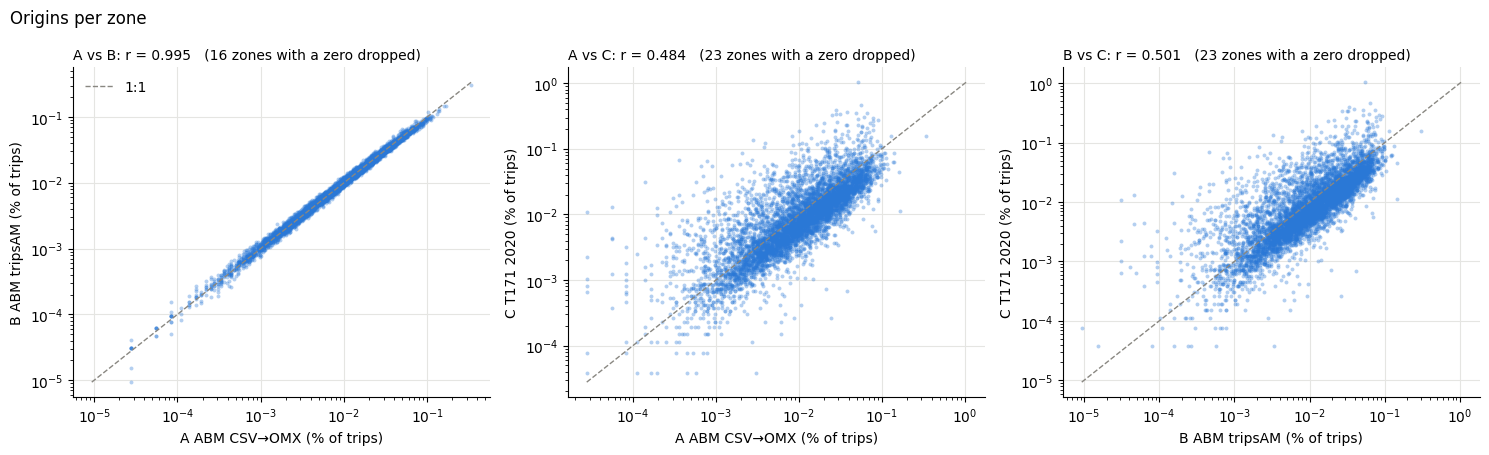

In [19]:
# 9a. Origins per zone: one panel per pair, log-log with 1:1 line

def trip_end_scatter(kind):
    fig, axes = plt.subplots(1, len(PAIRS), figsize=(5 * len(PAIRS), 4.6))
    for ax, (x, y) in zip(axes, PAIRS):
        xs, ys = trip_ends[(x, kind)].to_numpy(), trip_ends[(y, kind)].to_numpy()
        keep = (xs > 0) & (ys > 0)
        ax.scatter(xs[keep], ys[keep], s=8, color='#2a78d6', alpha=0.35, linewidths=0)
        lo, hi = min(xs[keep].min(), ys[keep].min()), max(xs.max(), ys.max())
        ax.plot([lo, hi], [lo, hi], color='#898781', linewidth=1, linestyle='--', label='1:1')
        ax.set_xscale('log'); ax.set_yscale('log')
        ax.set_xlabel(f"{x} {LABELS[x]} ({UNIT})")
        ax.set_ylabel(f"{y} {LABELS[y]} ({UNIT})")
        r = trip_end_stats.loc[(f"{x}–{y}", kind), 'corr']
        ax.set_title(f"{x} vs {y}: r = {r:.3f}   ({(~keep).sum():,} zones with a zero dropped)",
                     loc='left', fontsize=10)
        ax.grid(color='#e5e5e2', linewidth=0.8); ax.set_axisbelow(True)
        ax.spines[['top', 'right']].set_visible(False)
    axes[0].legend(frameon=False)
    fig.suptitle(f"{'Origins' if kind == 'orig' else 'Destinations'} per zone", x=0.01, ha='left')
    fig.tight_layout()

trip_end_scatter('orig')

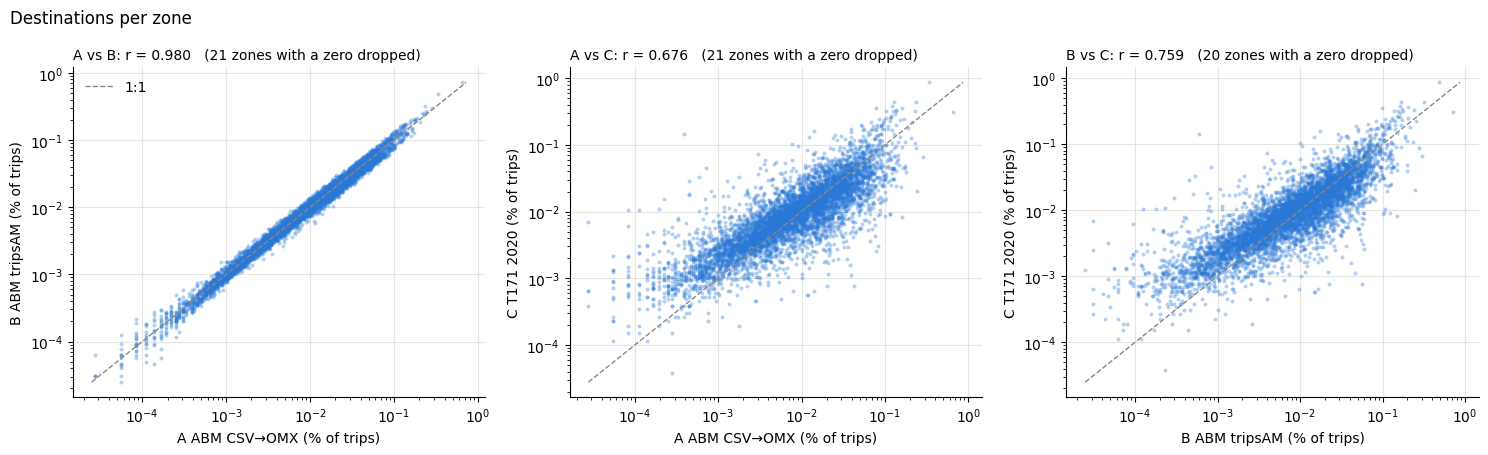

In [20]:
# 9b. Destinations per zone

trip_end_scatter('dest')

In [21]:
# 10. Zones with the largest trip-end differences for each pair

TOP_N = 20

def top_zone_diffs(x, y, kind, n=TOP_N):
    df = pd.DataFrame({x: trip_ends[(x, kind)], y: trip_ends[(y, kind)]})
    df[f"{y}-{x}"] = df[y] - df[x]
    return df.reindex(df[f"{y}-{x}"].abs().nlargest(n).index).reset_index()

KIND = 'orig'   # or 'dest'
pd.concat({f"{x}–{y} ({KIND})": top_zone_diffs(x, y, KIND) for x, y in PAIRS}, axis=1)

A–B (orig)                    A–C (orig)                   B–C (orig)  \
         zone     A     B    B-A       zone     A     C   C-A       zone   
0        1583 0.337 0.308 -0.029       3388 0.052 1.034 0.982       3388   
1        2169 0.168 0.147 -0.021        297 0.056 0.458 0.402        297   
2          94 0.112 0.091 -0.021        554 0.028 0.394 0.366        554   
3         170 0.131 0.112 -0.018         87 0.038 0.371 0.333         87   
4        4112 0.103 0.120  0.017        547 0.032 0.344 0.312        547   
5        2799 0.140 0.123 -0.016        302 0.028 0.339 0.311        302   
6        2003 0.161 0.145 -0.016        248 0.025 0.334 0.309        248   
7        1204 0.118 0.102 -0.016       1133 0.048 0.352 0.304       1133   
8        1525 0.090 0.074 -0.016        303 0.066 0.352 0.286        303   
9         548 0.072 0.087  0.016        346 0.061 0.301 0.240        346   
10        550 0.050 0.066  0.015         61 0.051 0.290 0.239         61   
11       3001 0.107 0.092 -0.015       2329 0.029 0.261 0.232       2329   
12       3006 0.081 0.066 -0.014         85 0.020 0.245 0.225         85   
13       3590 0.089 0.075 -0.014        488 0.016 0.230 0.214        488   
14        538 0.074 0.088  0.014       2321 0.079 0.291 0.212       2321   
15        124 0.107 0.094 -0.014        246 0.038 0.232 0.194       2518   
16       2731 0.084 0.071 -0.013       1317 0.089 0.280 0.191        246   
17         97 0.087 0.075 -0.013       2518 0.077 0.268 0.191       1317   
18        389 0.048 0.060  0.013       2336 0.037 0.227 0.190       2336   
19       3316 0.084 0.071 -0.013        347 0.052 0.231 0.179        546   

                      
       B     C   C-B  
0  0.055 1.034 0.979  
1  0.064 0.458 0.395  
2  0.033 0.394 0.361  
3  0.039 0.371 0.332  
4  0.033 0.344 0.311  
5  0.031 0.339 0.308  
6  0.027 0.334 0.307  
7  0.051 0.352 0.301  
8  0.073 0.352 0.279  
9  0.061 0.301 0.240  
10 0.051 0.290 0.239  
11 0.031 0.261 0.230  
12 0.021 0.245 0.224  
13 0.018 0.230 0.212  
14 0.085 0.291 0.206  
15 0.076 0.268 0.192  
16 0.042 0.232 0.190  
17 0.092 0.280 0.188  
18 0.040 0.227 0.188  
19 0.012 0.187 0.175

In [22]:
# 11a. OD-cell statistics for each pair

def cell_stats(x, y):
    mx, my = cmp[x], cmp[y]
    s = pair_stats(mx, my)
    s[f'% of {x} in cells where {y}=0'] = 100 * mx[my == 0].sum() / mx.sum()
    s[f'% of {y} in cells where {x}=0'] = 100 * my[mx == 0].sum() / my.sum()
    return s

for x, y in PAIRS:
    print(f"--- {x}–{y} ({UNIT})")
    print(pd.Series(cell_stats(x, y)).to_string(float_format='{:,.4g}'.format))

--- A–B (% of trips)
corr                           0.9859
R²                             0.9719
RMSE                        1.191e-05
%RMSE                           417.7
sum |diff|                      28.32
|diff| % of mean total          28.32
% of A in cells where B=0    0.007099
% of B in cells where A=0       5.727
--- A–C (% of trips)
corr                           0.3283
R²                             0.1078
RMSE                        5.914e-05
%RMSE                           2,074
sum |diff|                      142.3
|diff| % of mean total          142.3
% of A in cells where C=0       37.55
% of C in cells where A=0       53.39
--- B–C (% of trips)
corr                           0.3716
R²                             0.1381
RMSE                        5.185e-05
%RMSE                           1,818
sum |diff|                      138.9
|diff| % of mean total          138.9
% of B in cells where C=0       39.62
% of C in cells where B=0        50.8


Cells nonzero in both: 1,222,825; only A: 100; only B: 198,143


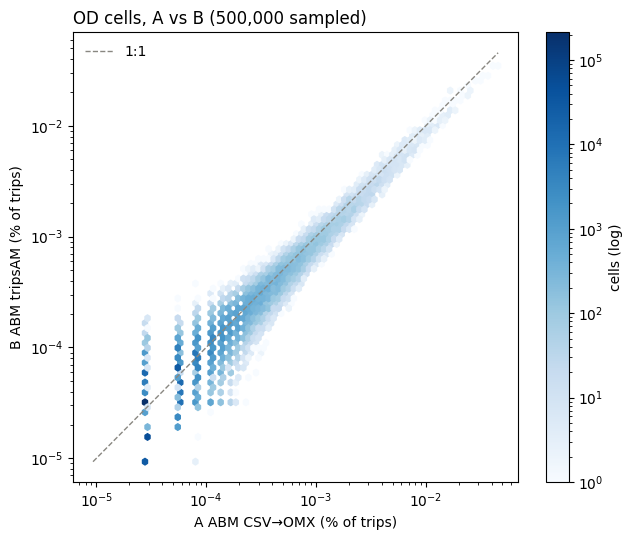

In [23]:
# 11b. OD-cell density plot for one pair (cells nonzero in both, sampled)

PAIR = ('A', 'B')
MAX_POINTS = 500_000

x, y = PAIR
mx, my = cmp[x].ravel(), cmp[y].ravel()
both = np.flatnonzero((mx > 0) & (my > 0))
print(f"Cells nonzero in both: {both.size:,}; only {x}: {int(((mx > 0) & (my == 0)).sum()):,}; "
      f"only {y}: {int(((mx == 0) & (my > 0)).sum()):,}")
rng = np.random.default_rng(0)
pick = rng.choice(both, size=min(MAX_POINTS, both.size), replace=False)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
hb = ax.hexbin(mx[pick], my[pick], xscale='log', yscale='log', bins='log', gridsize=70, cmap='Blues', mincnt=1)
lo, hi = min(mx[pick].min(), my[pick].min()), max(mx[pick].max(), my[pick].max())
ax.plot([lo, hi], [lo, hi], color='#898781', linewidth=1, linestyle='--', label='1:1')
ax.set_xlabel(f"{x} {LABELS[x]} ({UNIT})")
ax.set_ylabel(f"{y} {LABELS[y]} ({UNIT})")
ax.set_title(f"OD cells, {x} vs {y} ({len(pick):,} sampled)", loc='left')
ax.legend(frameon=False, loc='upper left')
fig.colorbar(hb, ax=ax, label='cells (log)')
fig.tight_layout()

50-zone blocks: (119, 119)


,corr,R²,RMSE,%RMSE,sum |diff|,|diff| % of mean total
A–B,0.997,0.994,0.004,60.013,12.244,12.244
A–C,0.800,0.640,0.023,327.706,67.819,67.819
B–C,0.826,0.682,0.020,276.917,60.422,60.422


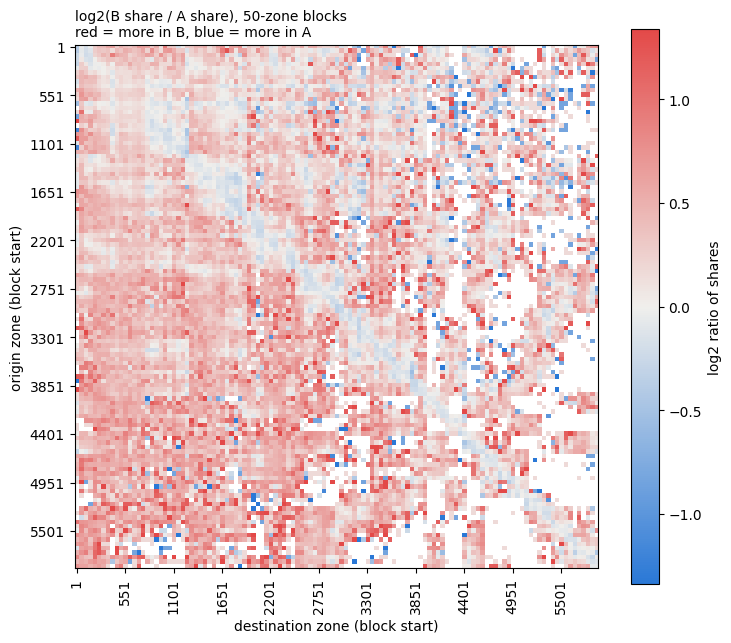

In [24]:
# 12. Block aggregation: consecutive-zone blocks, stats + log2 share ratio heatmap for PAIR

BLOCK = 50  # zones per block

def to_blocks(m, block=BLOCK):
    nb = int(np.ceil(m.shape[0] / block))
    padded = np.zeros((nb * block, nb * block))
    padded[:m.shape[0], :m.shape[1]] = m
    return padded.reshape(nb, block, nb, block).sum(axis=(1, 3))

blocks = {k: to_blocks(m) for k, m in cmp.items()}
print(f"{BLOCK}-zone blocks: {blocks['A'].shape}")
display(pd.DataFrame({f"{x}–{y}": pair_stats(blocks[x], blocks[y]) for x, y in PAIRS}).T)

# Ratio of shares (always normalised so the map shows spatial pattern, not total differences)
x, y = PAIR
bx, by = blocks[x] / blocks[x].sum(), blocks[y] / blocks[y].sum()
with np.errstate(divide='ignore', invalid='ignore'):
    log_ratio = np.ma.masked_invalid(np.log2(by / bx))
lim = np.nanpercentile(np.abs(log_ratio.compressed()), 98)

diverging = LinearSegmentedColormap.from_list('blue_gray_red', ['#2a78d6', '#f0efec', '#e34948'])
nb = blocks['A'].shape[0]
block_zones = common[np.minimum(np.arange(nb) * BLOCK, len(common) - 1)]
fig, ax = plt.subplots(figsize=(7.5, 6.5))
img = ax.imshow(log_ratio, cmap=diverging, vmin=-lim, vmax=lim, interpolation='nearest')
ticks = np.arange(0, nb, max(1, nb // 10))
ax.set_xticks(ticks, block_zones[ticks], rotation=90)
ax.set_yticks(ticks, block_zones[ticks])
ax.set_xlabel('destination zone (block start)')
ax.set_ylabel('origin zone (block start)')
ax.set_title(f"log2({y} share / {x} share), {BLOCK}-zone blocks\nred = more in {y}, blue = more in {x}",
             loc='left', fontsize=10)
fig.colorbar(img, ax=ax, label='log2 ratio of shares')
fig.tight_layout()

In [25]:
# 13. Single-zone drill-down: trips to/from a zone in each source and its top partners

def zone_compare(zone, n=10):
    i = zone_index.get_loc(zone)
    display(pd.DataFrame({
        f"{k} ({UNIT})": {'origins': m[i].sum(), 'destinations': m[:, i].sum(), 'intrazonal': m[i, i]}
        for k, m in cmp.items()
    }).T)
    display(pd.concat(
        {f"{k} top destinations": pd.Series(m[i], index=zone_index, name=UNIT).nlargest(n).reset_index()
         for k, m in cmp.items()},
        axis=1,
    ))

zone_compare(int(trip_ends[('A', 'orig')].idxmax()))

,origins,destinations,intrazonal
A (% of trips),0.337,0.650,0.058
B (% of trips),0.308,0.724,0.058
C (% of trips),0.158,0.311,0.005


A top destinations            B top destinations             \
                zone % of trips               zone % of trips   
0               1583      0.058               1583      0.058   
1               1580      0.007               1580      0.006   
2               1582      0.006               1582      0.006   
3               1576      0.004               1576      0.004   
4               1563      0.003               1581      0.003   
5               1574      0.003               1563      0.003   
6               1595      0.003               1574      0.003   
7               1581      0.003               1595      0.003   
8               1548      0.003               1575      0.002   
9               1561      0.002               1548      0.002   

  C top destinations             
                zone % of trips  
0               1583      0.005  
1                533      0.001  
2               1590      0.001  
3               1565      0.001  
4                538      0.001  
5               1563      0.001  
6               1570      0.001  
7                347      0.001  
8                358      0.001  
9                576      0.001

In [26]:
# 14. C by purpose: do A and B (AM peak) look more like T171 work or non-work trips?

c_ends = {}
for n, m in {**c_aligned, 'total': aligned['C']}.items():
    c_ends[(n, 'orig')] = m.sum(axis=1)
    c_ends[(n, 'dest')] = m.sum(axis=0)

rows = {}
for k in ('A', 'B'):
    for kind in ('orig', 'dest'):
        rows[(k, kind)] = {f"C {n}": np.corrcoef(trip_ends[(k, kind)], c_ends[(n, kind)])[0, 1]
                           for n in [*C_NAMES, 'total']}
print("Correlation of zone trip ends with C by purpose")
display(pd.DataFrame(rows).T)
print("C purpose split:", {n: f"{100 * m.sum() / aligned['C'].sum():.1f}%" for n, m in c_aligned.items()})

Correlation of zone trip ends with C by purpose


C work  C non-work  C total
A orig   0.798       0.279    0.484
  dest   0.653       0.644    0.676
B orig   0.816       0.292    0.501
  dest   0.751       0.703    0.759

C purpose split: {'work': '40.4%', 'non-work': '59.6%'}
